# Transformer-Based LLM Chatbot using Hugging Face and Gradio

Name: Rohith John |  Roll No: 24BAD100

# PART A: ENVIRONMENT SETUP AND MODEL SELECTION

In [1]:
%pip -q install "transformers>=4.45,<5" "gradio>=4.44,<6" accelerate sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.7/87.7 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.1 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 31.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.6/325.6 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 94.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 462.4/462.4 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 53.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 96.3 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 61.8 MB/s eta 0:00:00:00:01
ERR

In [2]:
import os, time, json, gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Model:", MODEL_ID)
print("No API key required. Internet access is needed for first model download.")

PyTorch: 2.11.0+cu128
Device: cuda
Model: Qwen/Qwen2.5-0.5B-Instruct
No API key required. Internet access is needed for first model download.


## Load Pretrained Model

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32,
    low_cpu_mem_usage=True
).to(DEVICE)
model.eval()
print("Model and tokenizer loaded successfully")
print("Parameters (millions):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model and tokenizer loaded successfully
Parameters (millions): 494.0


# PART B: PROMPT HANDLING AND RESPONSE GENERATION

## Chatbot Response Function

In [4]:
SYSTEM_MESSAGE = "You are a helpful educational chatbot. Give clear, concise, accurate answers. If unsure, say so."
MAX_HISTORY_TURNS = 3

def generate_response(message, history=None, max_new_tokens=120):
    if not isinstance(message, str) or not message.strip():
        return "Please enter a message."
    history = history or []
    messages = [{"role": "system", "content": SYSTEM_MESSAGE}]
    for turn in history[-MAX_HISTORY_TURNS:]:
        if isinstance(turn, dict):
            user = turn.get("user", "")
            assistant = turn.get("assistant", "")
        else:
            user, assistant = turn
        if user:
            messages.append({"role": "user", "content": str(user)})
        if assistant:
            messages.append({"role": "assistant", "content": str(assistant)})
    messages.append({"role": "user", "content": message.strip()})
    try:
        inputs = tokenizer.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True,
            return_tensors="pt"
        ).to(DEVICE)
        with torch.inference_mode():
            output = model.generate(
                inputs, max_new_tokens=max_new_tokens,
                do_sample=False, pad_token_id=tokenizer.eos_token_id
            )
        reply = tokenizer.decode(output[0][inputs.shape[-1]:], skip_special_tokens=True).strip()
        return reply or "No response was generated."
    except (RuntimeError, ValueError) as exc:
        return f"Generation error: {type(exc).__name__}: {exc}"

print("Prompt: Hello! Introduce yourself briefly.")
print("Response:", generate_response("Hello! Introduce yourself briefly."))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Prompt: Hello! Introduce yourself briefly.
Response: Hello! I'm here to help you with any questions or information you might need. How can I assist you today?


## Test Five Prompts

In [5]:
test_prompts = [
    "What is artificial intelligence? Answer in two sentences.",
    "Explain machine learning to a beginner.",
    "Write a short motivational message for students.",
    "Give three Python programming tips.",
    "What is the difference between a chatbot and a search engine?"
]
records = []
for i, prompt in enumerate(test_prompts, 1):
    start = time.time()
    reply = generate_response(prompt)
    records.append({"Test": i, "Prompt": prompt, "Response": reply, "Seconds": round(time.time()-start, 2)})
    print(f"\nTest {i} | {prompt}\n{reply}\n")
test_results = pd.DataFrame(records)
display(test_results)


Test 1 | What is artificial intelligence? Answer in two sentences.
Artificial Intelligence (AI) refers to the simulation of human intelligence processes by machines using algorithms and statistical models. It involves creating systems that can perform tasks that typically require human intelligence, such as visual perception, speech recognition, decision-making, and problem-solving.


Test 2 | Explain machine learning to a beginner.
Machine learning is a type of artificial intelligence that allows computers to learn from data and improve their performance over time without being explicitly programmed. It's based on the idea that systems can learn from experience and make decisions or predictions based on patterns in the data.

Here’s a step-by-step explanation for beginners:

1. **Data Collection**: First, you need to gather data that contains information about what you want your computer to do with it. This could be anything from images of cats to text messages to financial transacti

,Test,Prompt,Response,Seconds
0,1,What is artificial intelligence? Answer in two...,Artificial Intelligence (AI) refers to the sim...,1.54
1,2,Explain machine learning to a beginner.,Machine learning is a type of artificial intel...,3.51
2,3,Write a short motivational message for students.,"""Remember, every step forward is a victory, no...",1.23
3,4,Give three Python programming tips.,Certainly! Here are three Python programming t...,3.42
4,5,What is the difference between a chatbot and a...,A chatbot and a search engine serve different ...,3.44


# PART C: BUILDING THE CHATBOT INTERFACE

## Gradio Chatbot with Conversation History and Clear Chat

In [6]:
import gradio as gr
print("Gradio version:", gr.__version__)

def chat_reply(message, history):
    history = history or []
    prior = []
    for turn in history:
        if turn.get("role") == "user":
            prior.append({"user": str(turn.get("content", "")), "assistant": ""})
        elif turn.get("role") == "assistant" and prior:
            prior[-1]["assistant"] = str(turn.get("content", ""))
    return generate_response(message, prior)

chat_app = gr.ChatInterface(
    fn=chat_reply,
    type="messages",
    title="Transformer LLM Chatbot",
    description="Qwen2.5-0.5B-Instruct | Hugging Face Transformers | Gradio",
    examples=["Hello!", "Explain neural networks simply.", "Give me three study tips."],
    chatbot=gr.Chatbot(type="messages", height=400)
)
print("Gradio application created. Run the launch cell to open the interface.")

Gradio version: 5.50.0
Gradio application created. Run the launch cell to open the interface.


/tmp/ipykernel_49/940546386.py:20: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chatbot=gr.Chatbot(type="messages", height=400)


## Launch Chatbot

In [7]:
# In Kaggle, enable Internet in notebook Settings before launching.
# The cell stays running while the chat interface is active; this is normal.
chat_app.launch(share=True, debug=False, show_error=True)
# Temporary public think that changes whenever session restarts.

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://462898ecf50cc1170a.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# PART D: TESTING AND DEPLOYMENT

## Prompt Testing Results

,Test,Prompt,Response,Seconds
0,1,What is artificial intelligence? Answer in two...,Artificial Intelligence (AI) refers to the sim...,1.54
1,2,Explain machine learning to a beginner.,Machine learning is a type of artificial intel...,3.51
2,3,Write a short motivational message for students.,"""Remember, every step forward is a victory, no...",1.23
3,4,Give three Python programming tips.,Certainly! Here are three Python programming t...,3.42
4,5,What is the difference between a chatbot and a...,A chatbot and a search engine serve different ...,3.44


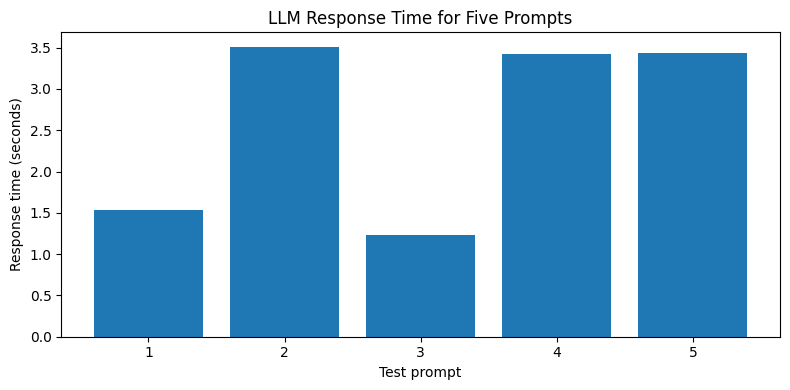

In [8]:
display(test_results)
plt.figure(figsize=(8, 4))
plt.bar(test_results["Test"].astype(str), test_results["Seconds"])
plt.xlabel("Test prompt")
plt.ylabel("Response time (seconds)")
plt.title("LLM Response Time for Five Prompts")
plt.tight_layout()
plt.show()

## Evaluation and Limitations

In [9]:
evaluation = pd.DataFrame({
    "Criterion": ["Relevance", "Readability", "Consistency", "Factual accuracy", "Safety and bias"],
    "Observation": ["Review answers against prompts", "Check clarity and grammar", "Repeat prompts and compare", "Verify facts using reliable sources", "Review for harmful or biased content"]
})
display(evaluation)
print("Limitations: The model can hallucinate, produce biased answers, and respond slowly on CPU.")
print("Gradio share links are temporary; do not treat them as permanent public deployment.")

,Criterion,Observation
0,Relevance,Review answers against prompts
1,Readability,Check clarity and grammar
2,Consistency,Repeat prompts and compare
3,Factual accuracy,Verify facts using reliable sources
4,Safety and bias,Review for harmful or biased content


Limitations: The model can hallucinate, produce biased answers, and respond slowly on CPU.
Gradio share links are temporary; do not treat them as permanent public deployment.


## Save Source Files and Sample Outputs

In [10]:
OUTPUT_DIR = "/kaggle/working/llm_chatbot_submission"
os.makedirs(OUTPUT_DIR, exist_ok=True)

app_source = r'''import torch
import gradio as gr
from transformers import AutoTokenizer, AutoModelForCausalLM
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE)
model.eval()

def respond(message, history):
    if not message.strip():
        return "Please enter a message."
    messages = [{"role": "system", "content": "You are a helpful educational chatbot."}]
    messages.extend(history[-6:])
    messages.append({"role": "user", "content": message})
    inputs = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        output = model.generate(inputs, max_new_tokens=120, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(output[0][inputs.shape[-1]:], skip_special_tokens=True).strip()

app = gr.ChatInterface(fn=respond, type="messages", title="Transformer LLM Chatbot")
if __name__ == "__main__":
    app.launch()
'''
with open(os.path.join(OUTPUT_DIR, "app.py"), "w", encoding="utf-8") as f:
    f.write(app_source)
with open(os.path.join(OUTPUT_DIR, "requirements.txt"), "w", encoding="utf-8") as f:
    f.write("torch\ntransformers>=4.45,<5\ngradiO>=4.44,<6\naccelerate\nsentencepiece\n".replace("gradiO", "gradio"))
test_results.to_csv(os.path.join(OUTPUT_DIR, "sample_outputs.csv"), index=False)
evaluation.to_csv(os.path.join(OUTPUT_DIR, "evaluation_checklist.csv"), index=False)
print("Files saved:", os.listdir(OUTPUT_DIR))
print("Submission directory:", OUTPUT_DIR)

Files saved: ['app.py', 'evaluation_checklist.csv', 'sample_outputs.csv', 'requirements.txt']
Submission directory: /kaggle/working/llm_chatbot_submission
